# LASSI - Power Efficiency

***OLLAMA API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

## Setup

In [1]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline
%aimport lassi.get_power

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [2]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.

    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]
    """
    
    app_folder_name = "lid-driven-cavity"

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    if source_lang == "CUDA":
        code_compiler = "nvcc"
        code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
        # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM LMSTUDIO
    # model = "lmstudio-community/Meta-Llama-3-8B-Instruct-GGUF/"
    # model = "TheBloke/CodeLlama-13B-Instruct-GGUF"
    # model = "lmstudio-community/starcoder2-15b-instruct-v0.1-GGUF" - couldn;t generate anything
    # model = "lmstudio-community/stable-code-instruct-3b-GGUF" - couldn't compile, but 'worked'
    # model = "microsoft/Phi-3-mini-4k-instruct-gguf" - generated garbage, and slow
    # model = "lmstudio-community/codegemma-1.1-7b-it-GGUF" - generated code, faster, but not compiled -- more tries
    # model = "lmstudio-community/Codestral-22B-v0.1-GGUF"  # - nice large context size 32768 -- load it on aiop01 at 28 gpu layers

    # -- FROM OLLAMA
    model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model_coder = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    model_coder = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "codestral"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 128000

    # ASSIGN LLM API SOURCE:
    if "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "01test_betterpower_withcontext"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context,
            context_knowledge_selection, code_compiler, code_compiler_kwds, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


Unloading Ollama server...

Unload LLM:
 {"model":"deepseek-r1:70b","created_at":"2025-02-04T02:28:45.495141484Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   167  100   122  100    45  97288  35885 --:--:-- --:--:-- --:--:--  163k


Unloading Ollama server...

Unload LLM:
 {"model":"deepseek-coder-v2:16b-lite-instruct-fp16","created_at":"2025-02-04T02:28:45.502334946Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   217  100   147  100    70   118k  57660 --:--:-- --:--:-- --:--:--  211k


***** EX

Waiting for the system to settle down...: 100%|██████████████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 10.235139 (s)
GPU power data has been written to source_CUDA_gpu_power_results.csv


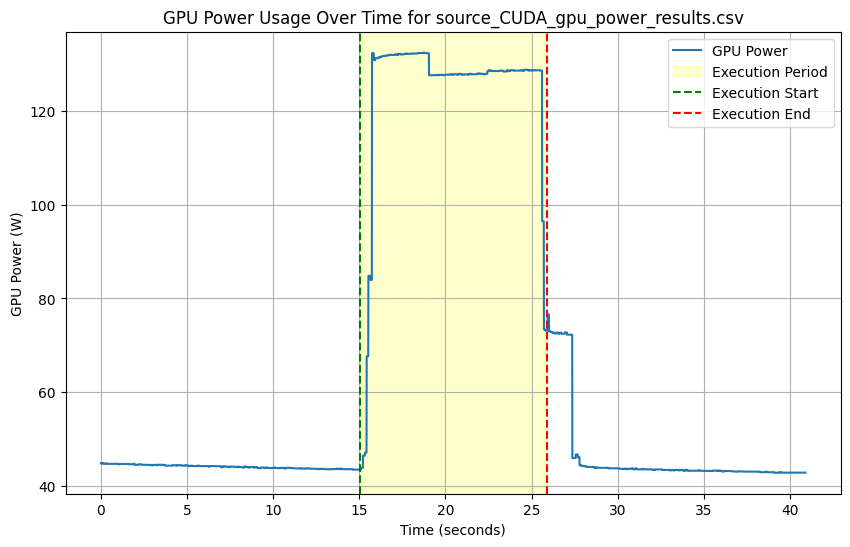

Start time: 15.015 -- End time: 25.887

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 10.87 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000373 kWh
  0.3734 Wh
  1344.12 J
Average GPU power: 123.65 W
Total Energy During Exe Runtime:   1344.12 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 10.87
GPU power data has been written to idle__gpu_power_results.csv


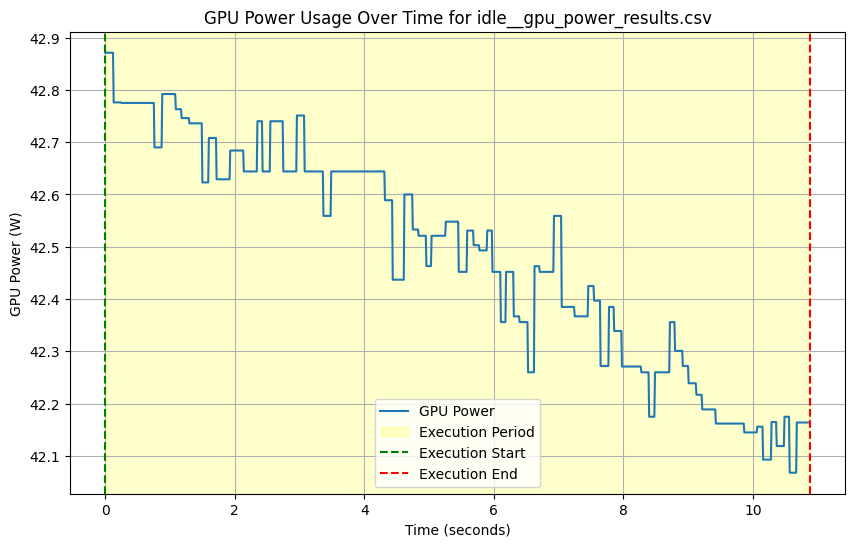

Start time: 0 -- End time: 10.881

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 10.88 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000128 kWh
  0.1284 Wh
  462.21 J
Average GPU power: 42.48 W
Total Energy During Exe Runtime:   462.21 J
----------------------------------------------------------------------------------------------------------------------------------------





----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----


GPU Memory Status:
 GPU 0: 637 MiB used, 40322 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total

--> ... prompt LLM to summarize context knowledge.




----- CONTEXT KNOWLEDGE SUMMARY -----
 (generated by the LLM)



To optimize CUDA code effectively, consider the following structured approach based on the thought process:

### 1. **Memory Hierarchy Optimization**
   - **Minimize Global Memory Access:** Use shared memory for frequently accessed data to reduce latency. Implement data caching by reading chunks into shared arrays before processing.
   - **Shared Memory Usage:** Structure data to minimize bank conflicts, ensuring efficient access patterns.

### 2. **Thread Cooperation and Warp-Level Optimization**
   - **Avoid Divergence:** Restructure conditional statements and loops to ensure all threads in a warp follow the same execution path. This reduces divergence and improves performance.
   - **Branch Predication:** Allow the compiler to use predication where possible, enabling uniform instruction execution across warps with some threads masked.

### 3. **Loop and Branch Optimization**
   - **Loop Unrolling:** Apply loop unrolling, possibly using `#pragma unroll`, to reduce overhead. Balance this by monitoring register usage to avoid increased resource consumption.
   - **Simplify Branches:** Keep branches simple to encourage compiler optimizations and reduce divergence.

### 4. **Math Function Efficiency**
   - **Specialized Functions:** Replace generic math functions with specialized ones (e.g., `sinpi` instead of `sin`, `exp2` instead of `pow(2, x)`) for optimized performance on GPU architectures.

### 5. **Synchronization Reduction**
   - **Minimize Synchronizations:** Reduce the number of global synchronizations like `__syncthreads()` to avoid unnecessary waiting, while ensuring race conditions are prevented.

### 6. **Register Blocking and Resource Management**
   - **Effective Register Use:** Utilize registers for frequently accessed data to minimize memory accesses, enhancing performance through faster access times.

### 7. **Architecture-Specific Optimizations**
   - **Volta and Beyond:** On newer GPUs, manage warp divergence with `__syncwarp()` when necessary, balancing the need for synchronization without introducing overhead.

### Implementation Strategy
- **Identify Bottlenecks:** Profile code to pinpoint areas where optimizations will have the most impact.
- **Refactor Code:** Address global memory accesses and divergent paths first, followed by loop and math function optimizations.
- **Educational Resources:** Consult CUDA best practices guides, examples, and courses for deeper insights into optimization techniques.

### Conclusion
Optimizing CUDA code requires a balanced approach, considering both algorithmic structure and hardware specifics. By focusing on memory hierarchy, thread cooperation, and efficient use of resources, significant performance improvements can be achieved while maintaining code readability and maintainability.

GPU Memory Status:
 GPU 0: 23859 MiB used, 17100 MiB free, 40960 MiB total
 GPU 1: 23744 MiB used, 17215 MiB free, 40960 MiB total

--> ... prompt LLM to describe the source code.




----- CODE DESCRIPTION and ANALYSIS -----
 (generated by the LLM)



To optimize the provided CUDA-based fluid simulation code, several key improvements can be made focusing on performance, readability, and robustness:

### 1. **Error Handling**
   - **Add Error Checking:** After each CUDA function call (e.g., `cudaMalloc`, `cudaMemcpy`, kernel launches), check for errors using `cudaGetLastError()`. This helps in debugging and ensures that GPU operations are successful.

### 2. **Memory Management**
   - **Minimize Data Transfers:** Reduce the number of `cudaMemcpy` calls within loops by keeping data on the GPU as much as possible. Use pinned memory for host data that requires frequent transfers to speed up the process.
   - **Use `cudaFreeHost()` for Pinned Memory:** Ensure that any pinned (page-locked) memory allocated with `cudaHostAlloc()` is properly freed using `cudaFreeHost()`.

### 3. **Loop Optimization**
   - **Remove Redundant Synchronizations:** Excessive use of `cudaDeviceSynchronize()` can hinder performance by preventing asynchronous execution. Remove unnecessary synchronizations unless explicitly needed for timing or correctness.
   - **Efficient Loop Unrolling:** While loop unrolling can help, ensure it's applied judiciously. Over-unrolling might not yield benefits and could increase register pressure.

### 4. **Kernel Optimization**
   - **Optimize Block and Grid Configuration:** Experiment with different block sizes to maximize occupancy on the target GPU architecture. Consider using a dynamic approach based on the actual hardware capabilities.
   - **Merge Kernels Where Possible:** Combine kernels that perform related tasks (e.g., boundary condition setting) to reduce global memory accesses and improve data locality.

### 5. **Performance Tools**
   - **Profile with NVIDIA Tools:** Use profiling tools like `nvprof` or the Visual Profiler to identify performance bottlenecks in the code. Focus on optimizing kernels with high execution times.
   - **Consider Async Data Transfers:** Overlap memory transfers with kernel executions using CUDA streams to hide latency, especially if the system has a dedicated transfer engine.

### 6. **Code Readability and Maintainability**
   - **Modularize Code:** Break down large functions into smaller, more manageable functions or classes to improve readability.
   - **Use Meaningful Variable Names:** Ensure variable names clearly indicate their purpose, making the code easier to understand and maintain.

### 7. **Output Handling**
   - **Limit Console Output:** Move `printf` statements outside of performance-critical loops or remove them for production runs to avoid slowing down execution.
   - **Optimize File Writing:** For large datasets, consider writing output in binary format instead of text to reduce I/O time.

### 8. **Boundary Conditions**
   - **Incorporate into Kernels:** If possible, handle boundary conditions within existing kernels rather than launching separate kernels, reducing global memory accesses and improving cache utilization.

By implementing these optimizations, the code should achieve better performance, be more maintainable, and provide clearer insights into its execution through proper error handling and profiling.

... (5 outputs left out)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/ollama_deepseek-r1:70b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext.cu', '-o', 'generated_codes/ollama_deepseek-r1:70b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext']

***** Compilation failed.
 Error message: 
generated_codes/ollama_deepseek-r1:70b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext.cu(1): error: this declaration has no storage class or type specifier
  uda
  ^

generated_codes/ollama_deepseek-r1:70b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext.cu(2): warning #1835-D: attribute "__global__" does not apply here
  __attribute__((global))
                 ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

generated_codes/ollama_deepseek-r1:

```cuda
__global__ void calculate_u(const Real dt,
                            const Real* __restrict__ F,
                            const Real* __restrict__ pres_red,
                            const Real* __restrict__ pres_black,
                            Real* __restrict__ u,
                            Real* __restrict__ max_u) {
    int row = (blockIdx.x * blockDim.x) + threadIdx.x + 1;
    int col = (blockIdx.y * blockDim.y) + threadIdx.y + 1;

    // Allocate shared memory to store max velocities
    __shared__ Real max_cache[BLOCK_SIZE];
    max_cache[threadIdx.x] = ZERO;

    int NUM_2 = NUM >> 1;
    Real new_u = ZERO, new_u2 = ZERO;

    if (col != NUM) {
        Real p_ij, p_ip1j;
        // Red point
        p_ij = pres_red[col * NUM + row];
        p_ip1j = pres_black[(col + 1) * NUM + row];

        new_u = F[col * (2 * NUM) + (2 * row) - (col & 1)] - (dt * (p_ip1j - p_ij) / dx);
        u[col * (2 * NUM) + (2 * row) - (col & 1)] = new_u;

        // Black point
        p_ij = pres_black[col * NUM + row];
        p_ip1j = pres_red[(col + 1) * NUM + row];

        new_u2 = F[col * (2 * NUM) + ((2 * row) - ((col + 1) & 1))] - (dt * (p_ip1j - p_ij) / dx);
        u[(col + 1) * (2 * NUM) - ((col + 1) & 1)] = new_u2;

        // Check for max of these two
        new_u = fmax(fabs(new_u), fabs(new_u2));

        if ((2 * row) == NUM) {
            // Also test for max velocity at vertical boundary
            new_u = fmax(new_u, fabs(u[col * (2 * NUM) + NUM + 1]));
        }
    } else {
        // Check for maximum velocity in boundary cells also
        new_u = fmax(fabs(u[NUM * (2 * NUM) + row]), fabs(u[row]));
        new_u = fmax(fabs(u[(NUM + 1) * (2 * NUM) + row]), new_u);
        new_u = fmax(fabs(u[row - 1]), new_u);
        new_u = fmax(fabs(u[(NUM + 1) * (2 * NUM) + row - 1]), new_u);
    }

    // Store maximum u for block from each thread
    max_cache[threadIdx.x] = new_u;

    // Synchronize threads in block to ensure all velocities stored
    __syncthreads();

    // Calculate maximum for block
    int i = BLOCK_SIZE >> 1;
    while (i != 0) {
        if (threadIdx.x < i) {
            max_cache[threadIdx.x] = fmax(max_cache[threadIdx.x], max_cache[threadIdx.x + i]);
        }
        __syncthreads();
        i >>= 1;
    }

    // Store block's maximum
    if (threadIdx.x == 0) {
        atomicMax(&max_u[blockIdx.y * gridDim.y + blockIdx.x], max_cache[0]);
    }
}
```

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/ollama_deepseek-r1:70b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext.cu', '-o', 'generated_codes/ollama_deepseek-r1:70b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext']

***** Compilation failed.
 Error message: 
generated_codes/ollama_deepseek-r1:70b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext.cu(1): error: this declaration has no storage class or type specifier
  uda
  ^

generated_codes/ollama_deepseek-r1:70b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext.cu(2): warning #1835-D: attribute "__global__" does not apply here
  __attribute__((global)) void calculate_u(const Real dt,
                 ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

gen

KeyboardInterrupt: 

In [3]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, context_knowledge_selection, code_compiler,
    code_compiler_kwds, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = "HeCBench/" + app_folder_name + "/"
input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + directory + "/" + file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    directory,
    file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

### TESTING ONLY

In [ ]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''